# Omni Helper - Send Files Between Project Members

**Omni Helper** moves files between users working in the same Omnisient project. Sharing requires the recipient's **User Address**; look it up with the project-members command in step 2 before you send anything.

## 1 · Load the extension

Magic command that loads Omni Helper into Jupyter as CLI-style commands.

In [ ]:
%load_ext omni_helper

## 2 · Fetch project members

Lists every active participant in the project, alongside their **User Address** and **Email**. You need the User Address, not the email, when sending a file to someone in step 3.

In [2]:
omni_helper project-members

+----+------------------------------------------+--------------+----------------------+
| SN |               User Address               | Project Name |        Email         |
+----+------------------------------------------+--------------+----------------------+
| 1  | 5a08204c9d6c1c76fe7bef346987f0108fb4fe6e |    00047     | usera@omnisient.com |
| 2  | 6178b33a245f70151a0ad011b8cac48a907191aa |    00047     | userb@omnisient.com  |
+----+------------------------------------------+--------------+----------------------+


## 3 · Send a file to a project member

`send-files` triggers an asynchronous copy to another project member. It needs a **filename** (after `--paths`, no spaces) and the recipient's **User Address** (after `--receiver`); replace both with your own values below. Only users within the same project can share files with each other. Check progress with the transfer-history command in step 4.

In [4]:
omni_helper send-files --paths filename.ipynb --receiver xyz123zyx456

Please check transfter history for completion status. Run omni_helper tranfer-history
REQUEST_ID: 999284c5-584b-405d-a47d-e8a9509561dd


## 4 · Check transfer history

Breaks down every file you've sent and received. A successful transfer also drops a shared folder into your workspace.

In [9]:
omni_helper transfer-history

FILES SENT TO ME:
+----+--------------------------+--------------+----------------------+---------+
| SN |           Date           |   Filename   |       Sent By        |  Status |
+----+--------------------------+--------------+----------------------+---------+
| 1  | 03:29:45 PM 13 June 2024 | Transfer.txt | userc@omnisient.com | success |
+----+--------------------------+--------------+----------------------+---------+
FILES SENT TO OTHERS:
+----+--------------------------+---------------------------+----------------------+---------+
| SN |           Date           |          Filename         |       Sent To        |  Status |
+----+--------------------------+---------------------------+----------------------+---------+
| 1  | 03:28:15 PM 13 June 2024 | Test_for_copy_User.ipynb | userc@omnisient.com | success |
+----+--------------------------+---------------------------+----------------------+---------+


## 5 · Visualize transfer history

A quick bar chart of files sent vs. received, built from the same data as the table above. With a longer history, group by **status** too so a failed transfer doesn't blend into the count.

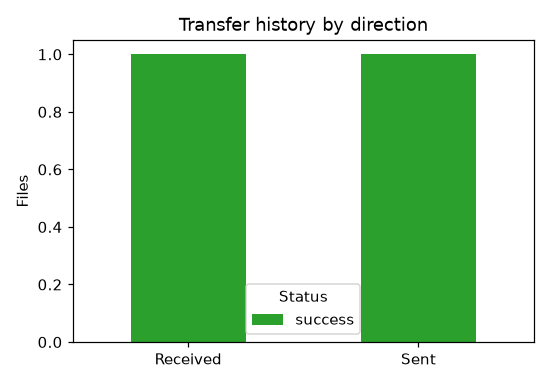

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# Same rows as the transfer-history table above
transfers = pd.DataFrame([
    {'direction': 'Received', 'filename': 'Transfer.txt', 'counterparty': 'wiehan@omnisient.com', 'status': 'success'},
    {'direction': 'Sent', 'filename': 'Test_for_copy_Ronny.ipynb', 'counterparty': 'wiehan@omnisient.com', 'status': 'success'},
])

counts = transfers.groupby(['direction', 'status']).size().unstack(fill_value=0)
ax = counts.plot(kind='bar', stacked=True, figsize=(5, 3.5), color=['#2ca02c'])
ax.set_title('Transfer history by direction')
ax.set_xlabel('')
ax.set_ylabel('Files')
ax.set_xticklabels(counts.index, rotation=0)
ax.legend(title='Status')
plt.tight_layout()
plt.show()

# Omni Hub - Read From the Data Warehouse

**Omni Hub** reads from the data warehouse, either your own Data Preparation area or a project's shared tables. Queries are written as SQL strings and submitted through the `%omni_hub` magic; the result is an Omni Hub object you convert to a pandas DataFrame with `.DataFrame()`.

## 1 · Load the extension

Magic command that loads Omni Hub into Jupyter.

In [ ]:
%load_ext omni_hub

## 2 · Query data

Define the query in SQL as a string, submit it through `%omni_hub`, then call `.DataFrame()` on the result to get a pandas DataFrame.

In [ ]:
# Define the query in sql format in a string
sql_query = """
    select 
        b.*,
        case
            when 
                a.PaymentDefault = 'No'
            then 
                0
            else
                1
        end
            as PaymentDefault_Ind
    from
        PAYMENTDEFAULTS_OVERLAP a
    inner join
        BUREAUPROFILES_FINAL b
    on
        a.[DW_ID_KEY] = b.[DW_ID_KEY]
"""

# Sumbit the query through Omni Hub
omni_data_object = %omni_hub {sql_query}

# Extract the pandas dataframe from the omni hub object
df = omni_data_object.DataFrame()

## 3 · Memory optimization for large tables

`%omni_hub` returns a **`ResultSet`** object. Converting it straight to pandas holds the data twice in memory: once as the `ResultSet`, once as the DataFrame. That can cause out-of-memory errors on large tables.

Export the `ResultSet` to CSV, delete it, then load the CSV into pandas instead. You only ever hold one copy:
1. Run the query with `%omni_hub`.
2. Save the result to CSV with `.csv("path")`.
3. Delete the original object (`del rs`).
4. Load the CSV into pandas with `pd.read_csv`.

In [ ]:
# 1) Run query via omni_hub
sql_query = f"SELECT TOP 10 * FROM {MY_TABLE}"
rs = %omni_hub {sql_query}

# 2) Save to CSV
csv_path = "my_table.csv"
rs.csv(csv_path)

# 3) Delete the ResultSet to free memory
del rs

# 4) Read CSV into Pandas
import pandas as pd
df = pd.read_csv(csv_path, low_memory=False)
df.head()

# Omni Lab - Write Data Back to Project Tables

**Omni Lab** writes data back to the data warehouse or a project's tables. Import it like any Python package, then hand a DataFrame to `.copy_to_project_tables()`; the write runs asynchronously.

## 1 · Import the package

Works like importing any standard Python package.

In [ ]:
import omni_lab

## 2 · Write data with `.copy_to_project_tables()`

`.copy_to_project_tables()` writes a DataFrame back to the data warehouse or a project's tables, and runs asynchronously. It takes three arguments:
- **DataFrame**: the data you're writing back as a table.
- **Project schema**: the project's database schema, typically `{company profile}_PRJ_{5-digit project code}` (e.g. `MYINSURANCE_PRJ_00001`). Find it on the project dashboard.
- **Table name**: the name of the table to create.

In [ ]:
# Define required parameters/arguments
project_id = "MYINSURANCE_PRJ_00001"
table_name = "JoinedTable"
dataframe = df

# Submit write request through omni lab
omni_lab.copy_to_project_tables(dataframe, project_id, table_name)

## Notes

- **Omni Helper** only shares files between users in the same project. Copying is asynchronous; confirm success with transfer-history.
- **Omni Hub** returns a `ResultSet`, not a DataFrame; call `.DataFrame()` to convert it, and use the CSV round-trip in step 3 for large tables to avoid holding two copies in memory.
- **Omni Lab** writes run asynchronously and target a project schema named `{company profile}_PRJ_{5-digit code}`, found on the project dashboard.